# EDA — EV Battery Failure Dataset

**estrutura → dados
ausentes → distribuição (antes) → tratamento → distribuição (depois) → relacional
(univariada, bivariada, multivariada)**.

**O dataset:** cada linha é um veículo elétrico, com dados cadastrais (marca, modelo, ano
de fabricação, tipo de veículo), dados da bateria (fabricante, química, capacidade em kWh)
e de uso (tipo de tração, odômetro em km). O alvo é `battery_failure`: 1 se o veículo
registrou falha de bateria, 0 caso contrário.


## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import entropy
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)


COR_NEUTRA = "lightgray"     
COR_CONTEXTO = "#bcdff1"    
COR_DESTAQUE = "#b5322d"     
COR_ALERTA = "black"         

## Carregando o Dataset

In [ ]:
# Funciona ao abrir o notebook pela raiz do projeto ou por notebooks/.
RAIZ = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
caminho = RAIZ / "data" / "raw" / "ev_battery_failure_dataset_columns.csv"

df = pd.read_csv(caminho)
df_raw = df.copy()  # Preserva os dados originais antes do tratamento.
df.head()


## 1. Princípio Estrutural

Antes de qualquer análise, preciso entender quantas linhas e colunas, tipo de cada coluna, se há ausentes e se há duplicadas.


### Dimensão e Tipos de Dados

In [3]:
df.shape

(20000, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   vehicle_id            20000 non-null  str    
 1   vehicle_brand         19356 non-null  str    
 2   vehicle_model         19180 non-null  str    
 3   vehicle_type          19356 non-null  str    
 4   manufacturing_year    19018 non-null  float64
 5   battery_manufacturer  19382 non-null  str    
 6   battery_chemistry     19278 non-null  str    
 7   battery_capacity_kwh  19310 non-null  float64
 8   drive_type            19274 non-null  str    
 9   odometer_km           19134 non-null  float64
 10  battery_failure       20000 non-null  int64  
dtypes: float64(3), int64(1), str(7)
memory usage: 1.7 MB


In [5]:
df.describe()

,manufacturing_year,battery_capacity_kwh,odometer_km,battery_failure
count,19018.000000,19310.000000,19134.000000,20000.0000
mean,2019.491482,87.124810,169562.067362,0.0692
std,2.864259,35.831323,74761.687034,0.2538
min,2015.000000,25.000000,500.000000,0.0000
25%,2017.000000,56.050000,116105.450000,0.0000
50%,2019.000000,87.315000,158148.000000,0.0000
75%,2022.000000,118.300000,211502.900000,0.0000
max,2024.000000,149.010000,450000.000000,1.0000


Com isso vemos que as três variáveis numéricas `manufacturing_year`, `battery_capacity_kwh`, `odometer_km` têm contagens diferentes de 20.000, o que indica que tem dados ausente nelas antes mesmo de rodar `isna()`.

### Duplicadas

In [6]:
df["vehicle_id"].duplicated().sum()

np.int64(0)

Sem duplicadas na chave

### Criando um rótulo legível para o alvo

In [7]:
df["status_bateria"] = np.where(df["battery_failure"] == 1, "Falha", "OK")
df["status_bateria"].value_counts()


status_bateria
OK       18616
Falha     1384
Name: count, dtype: int64

## 2. Dados Faltantes

In [8]:
nulos = df.isna().sum()
nulos_pct = (df.isna().mean() * 100).round(2)
pd.DataFrame({"n_ausentes": nulos, "%_ausentes": nulos_pct})


,n_ausentes,%_ausentes
vehicle_id,0,0.00
vehicle_brand,644,3.22
vehicle_model,820,4.10
vehicle_type,644,3.22
manufacturing_year,982,4.91
battery_manufacturer,618,3.09
battery_chemistry,722,3.61
battery_capacity_kwh,690,3.45
drive_type,726,3.63
odometer_km,866,4.33


**Discussão:** diferente do Heart Disease (só 2 colunas com ausentes), aqui **9 das 11
colunas** têm valores faltando, ou seja, quase todas as colunas exceto `vehicle_id` e o próprio alvo
`battery_failure`. Cada coluna isolada tem só ~3% a ~4% de ausentes, o que parece pouco, mas
com tantas colunas afetadas ao mesmo tempo o efeito acumulado é maior do que parece .


#### Identificando o mecanismo de dados ausentes

**Conhecimento de domínio.** Este dataset simula uma base cadastral/telemetria de frota:
- Campos cadastrais (`vehicle_brand`, `vehicle_model`, `vehicle_type`, `manufacturing_year`)
  podem faltar por preenchimento incompleto no momento do registro do veículo.
- Campos da bateria (`battery_manufacturer`, `battery_chemistry`, `battery_capacity_kwh`) podem
  faltar quando a ficha técnica do fabricante não foi integrada ao sistema.
- `odometer_km` e `drive_type` podem faltar por falha pontual de leitura de telemetria.

Não há, a princípio, um motivo óbvio para a ausência de qualquer um desses campos depender do
**valor que está faltando** (ex: um odômetro alto "se esconder" do sistema) é mais plausível
que sejam falhas de integração/cadastro, independentes do valor real. Isso aponta para
**MCAR ou MAR**, não MNAR, mas, como a aula lembrou, isso é hipótese de domínio, não certeza;
o próximo passo é olhar os dados para ver se essa hipótese se sustenta.


**As ausências ocorrem juntas?**

Na Aula 11, com só 2 colunas afetadas, um crosstab simples (2x2) resolvia. Como no meu caso o dataset escolhido tem muitas
colunas com muitos ausentes, uma correlação (ou heatmap) entre os indicadores de ausência passa
a fazer sentido . Em vez de uma tabela de contingência para cada par
de colunas, calculo a correlação de Spearman entre os indicadores binários de ausência
(1 = ausente, 0 = presente) de cada coluna e visualizo tudo de uma vez.


Colunas com ausentes: ['vehicle_brand', 'vehicle_model', 'vehicle_type', 'manufacturing_year', 'battery_manufacturer', 'battery_chemistry', 'battery_capacity_kwh', 'drive_type', 'odometer_km']


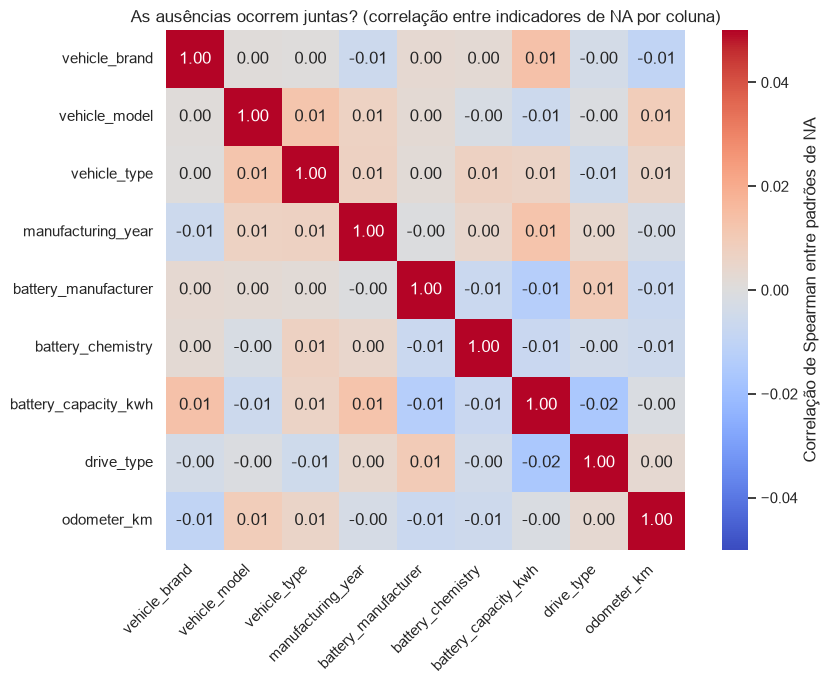

In [9]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)

indicador_ausencia = df[cols_com_ausentes].isna().astype(int)
corr_ausencia = indicador_ausencia.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_ausencia, cmap="coolwarm", center=0, vmin=-0.05, vmax=0.05,
            annot=True, fmt=".2f", square=True, cbar_kws={"label": "Correlação de Spearman entre padrões de NA"}, ax=ax)
ax.set_title("As ausências ocorrem juntas? (correlação entre indicadores de NA por coluna)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Leitura do heatmap:** todas as correlações ficam muito próximas de zero (a escala de
cor vai de -0.05 a 0.05 propositalmente, pra não "inflar" visualmente ruído). Isso indica que a
ausência em uma coluna **não** prevê ausência em outra, cada coluna parece ter seu próprio
processo de perda de dado, independente das demais. Isso é consistente com um mecanismo do
tipo **MCAR** (ausência aleatória, sem padrão sistemático entre colunas).


**Só isso não fecha a questão.** Ausência independente entre colunas não garante que a
ausência seja independente do **alvo**. Faço então um teste Qui-Quadrado entre "esta coluna
está ausente?" (sim/não) e `battery_failure`, para cada coluna com ausentes.


In [10]:
resultados_mecanismo = []
for col in cols_com_ausentes:
    tabela = pd.crosstab(df[col].isna(), df["battery_failure"])
    chi2, p, gl, esperado = stats.chi2_contingency(tabela)
    resultados_mecanismo.append({"coluna": col, "p_valor": round(p, 4), "associado_ao_alvo": p < 0.05})

pd.DataFrame(resultados_mecanismo).set_index("coluna")


,p_valor,associado_ao_alvo
coluna,,
vehicle_brand,0.1525,False
vehicle_model,1.0000,False
vehicle_type,0.5345,False
manufacturing_year,0.4053,False
battery_manufacturer,0.1833,False
battery_chemistry,0.4082,False
battery_capacity_kwh,0.0243,True
drive_type,0.6272,False
odometer_km,0.9375,False


**Discussão:** com exceção de `battery_capacity_kwh` (p ≈ 0.024, levemente abaixo de
0.05), nenhuma outra coluna mostra associação estatisticamente significativa entre "estar
ausente" e o veículo ter tido falha de bateria. Somando as duas evidências (ausências
independentes entre si + praticamente nenhuma associada ao alvo), a conclusão mais razoável é
**MCAR** para a maioria das colunas, com uma ressalva para `battery_capacity_kwh`, que merece
atenção caso seja usada como preditora principal em uma modelagem futura, já que a associação,
mesmo fraca, pode introduzir viés se ignorada.


## 3. Princípio Distribucional

In [11]:
VARS_QUANT = ["manufacturing_year", "battery_capacity_kwh", "odometer_km"]
VARS_QUALI = ["vehicle_brand", "vehicle_model", "vehicle_type", "battery_manufacturer",
              "battery_chemistry", "drive_type"]


desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)


,mean,median,std,min,max,skewness,kurtosis
manufacturing_year,2019.49,2019.00,2.86,2015.00,2024.00,0.01,-1.21
battery_capacity_kwh,87.12,87.32,35.83,25.00,149.01,-0.01,-1.21
odometer_km,169562.07,158148.00,74761.69,500.00,450000.00,0.85,0.86


**Discussão:** `manufacturing_year` e `battery_capacity_kwh` têm skewness perto de 0 e
kurtosis negativa (~-1.2), formato achatado, mais parecido com uma distribuição **uniforme**
do que com uma normal (faz sentido: capacidade de bateria e ano de fabricação tendem a se
espalhar de forma relativamente homogênea entre os modelos do catálogo). Já `odometer_km` tem
skewness de ~0.85 (assimetria à direita moderada), poucos veículos rodam muito mais que a
maioria, puxando a cauda direita, o que é fisicamente coerente (poucos veículos "campeões de
quilometragem", como frotas ou taxis).


### Distribuições de dados

Onde fizer sentido, comparo "OK" (azul) vs. "Falha" (vermelho), mantendo essa convenção
até a bivariada.


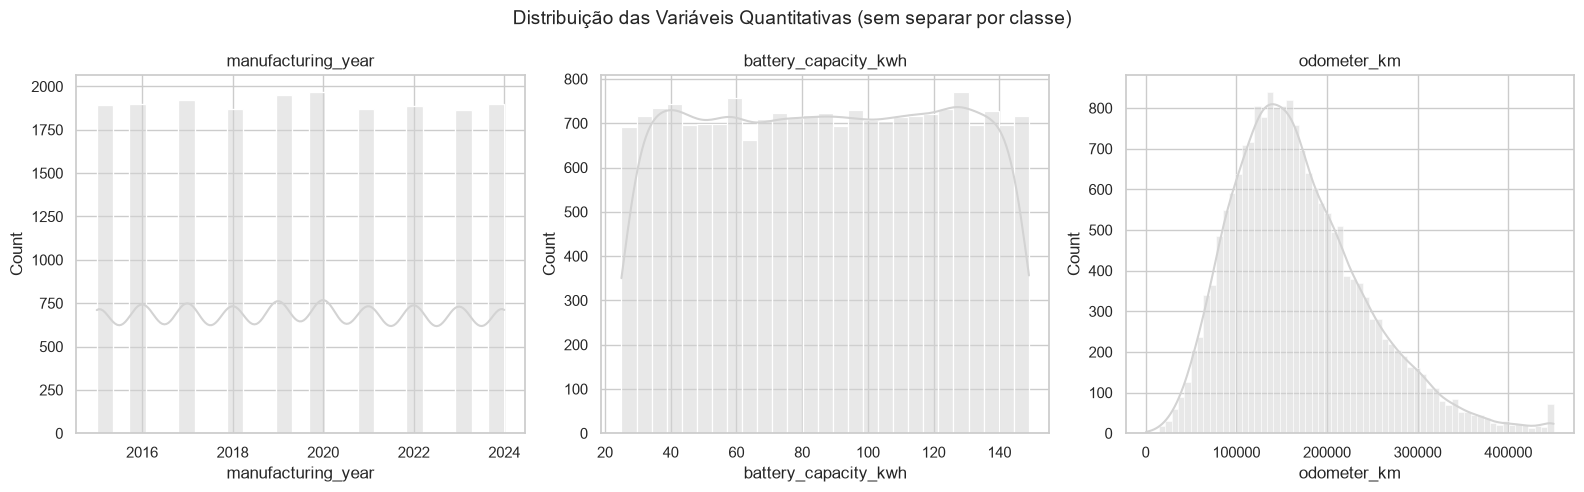

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()


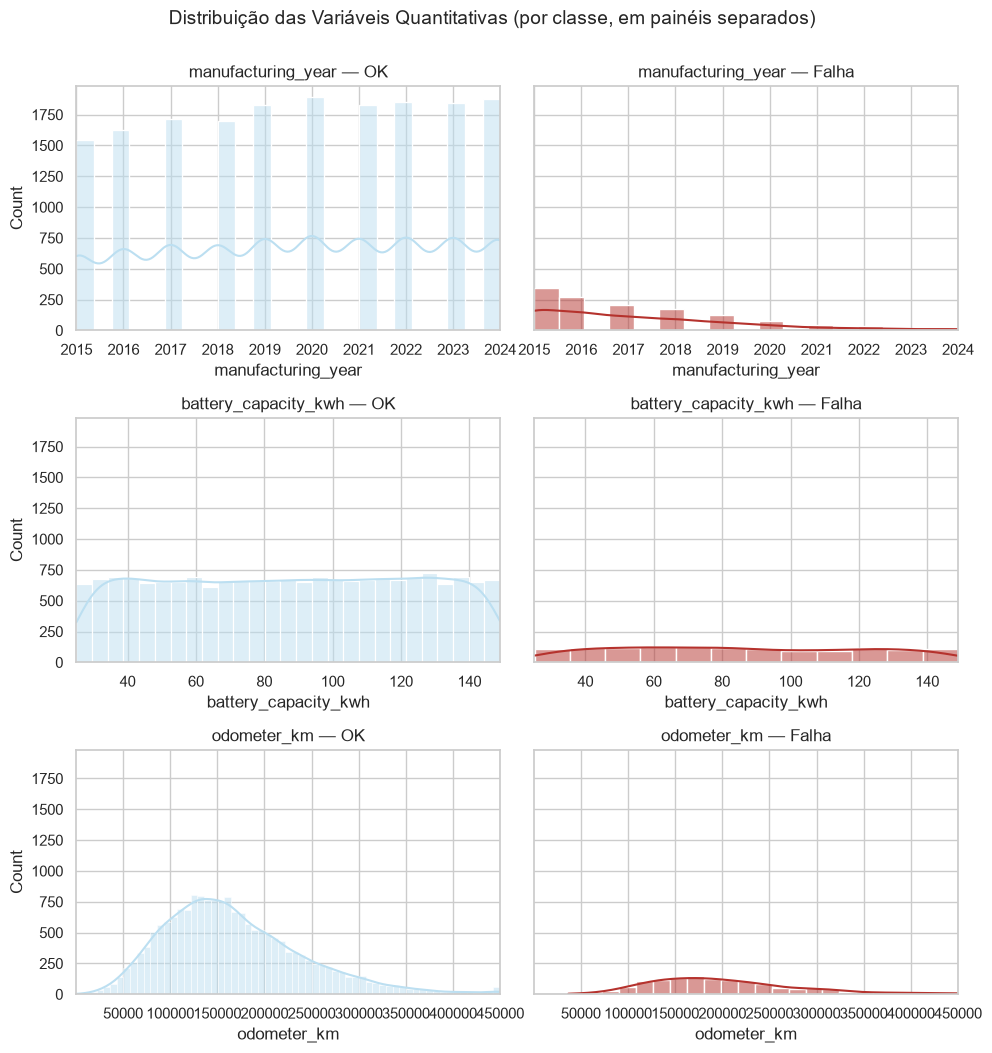

In [13]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("OK", COR_CONTEXTO), ("Falha", COR_DESTAQUE)]):
        subset = df[df["status_bateria"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()


**Discussão:** com a mesma escala de eixo X nas duas colunas, dá pra notar que
`manufacturing_year` puxa mais para anos antigos no grupo "Falha" (faz sentido: bateria mais
velha, mais chance de falhar) e `odometer_km` puxa mais para valores altos no grupo "Falha"
(mais uso, mais desgaste). `battery_capacity_kwh` não mostra diferença visual clara entre os
dois grupos.


#### Testes de Aderência

*Será que o odômetro segue uma distribuição normal?* Uso Shapiro-Wilk (teste de
aderência mais comum pra normalidade) + QQ-Plot como apoio visual, com `odometer_km`, a
variável que já parecia mais assimétrica na tabela acima.

**Nota técnica:** o Shapiro-Wilk fica sensível demais com `n` muito grande (rejeita a
normalidade por desvios triviais), e o próprio `scipy` recomenda não usar acima de ~5.000
observações. Como tenho 20.000 linhas, calculo o teste sobre uma amostra aleatória de 4.000
observações (com seed fixa, pra reprodutibilidade), em vez do dataset inteiro.


Shapiro-Wilk — odometer_km (amostra n=4000): estatística=0.9602, p-valor=8.567e-32
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


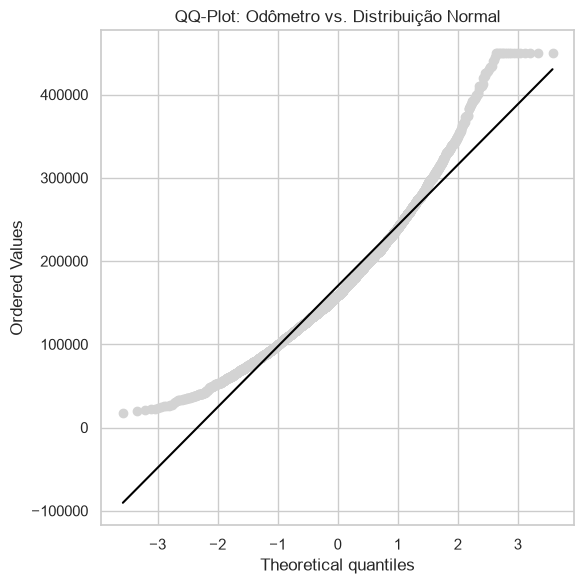

In [14]:
amostra_odometer = df["odometer_km"].dropna().sample(4000, random_state=42)

stat_sw, p_valor_sw = stats.shapiro(amostra_odometer)
print(f"Shapiro-Wilk — odometer_km (amostra n=4000): estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(amostra_odometer, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Odômetro vs. Distribuição Normal")
plt.tight_layout()
plt.show()


**Lendo:** se os pontos cinzas seguissem de perto a linha preta, `odometer_km`
seguiria uma normal. Aqui os pontos se afastam nas duas pontas (mais na direita), coerente com
a assimetria à direita já vista na tabela de skewness/kurtosis.

**Temos que ter cuidado com a interpretação:** com n=4.000 (nem pequeno, nem gigantesco) e três evidências
concordando, skewness > 0, QQ-Plot afastado da reta, Shapiro-Wilk rejeitando , o resultado é
razoavelmente confiável, não um artefato do tamanho da amostra. E como o teste **rejeitou** H0,
com isso, há evidência estatística **contra** a normalidade.


In [15]:
resultados_shapiro = []
for col in VARS_QUANT:
    amostra = df[col].dropna().sample(min(4000, df[col].dropna().shape[0]), random_state=42)
    stat, p = stats.shapiro(amostra)
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")


,estatistica,p_valor,rejeita_normalidade
variavel,,,
manufacturing_year,0.9377,0.0,True
battery_capacity_kwh,0.9548,0.0,True
odometer_km,0.9602,0.0,True


As três variáveis rejeitam normalidade, nenhuma delas deveria alimentar um teste
paramétrico que exija esse pressuposto sem antes considerar a alternativa não-paramétrica.


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher número de bins: para cada valor no
eixo X, mostra a proporção acumulada de observações menores ou iguais àquele valor. É útil pra
comparar duas distribuições lado a lado, onde as curvas se distanciam mais é onde a diferença
entre os grupos é mais perceptível. Fazendo com `odometer_km`, por classe.


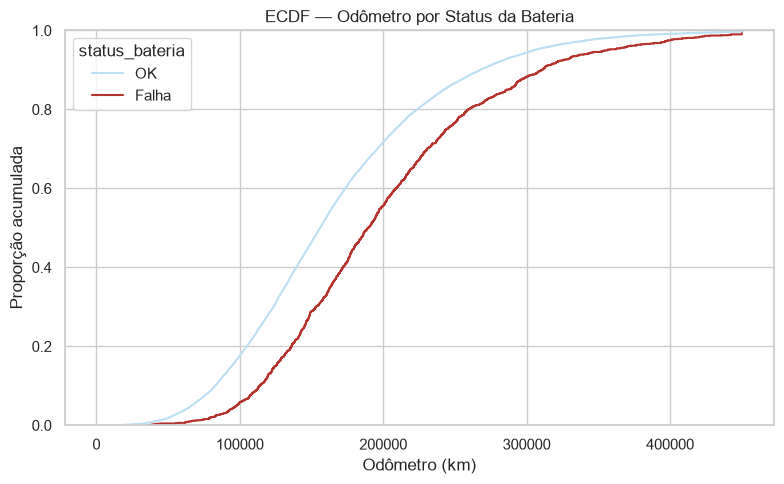

In [16]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="odometer_km", hue="status_bateria",
             palette={"OK": COR_CONTEXTO, "Falha": COR_DESTAQUE})
plt.title("ECDF — Odômetro por Status da Bateria")
plt.xlabel("Odômetro (km)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()


**Leitura:** a curva "Falha" (vermelha) fica visivelmente à direita da curva "OK" (azul)
na maior parte do eixo, ou seja, pra qualquer quilometragem de corte, uma fração maior dos
veículos "OK" já ficou abaixo dela do que dos veículos "Falha". Isso é evidência visual de que
veículos com falha tendem a ter rodado mais quilômetros, reforçando o que já vimos no
histograma por classe.


### Métricas de Tendência Central

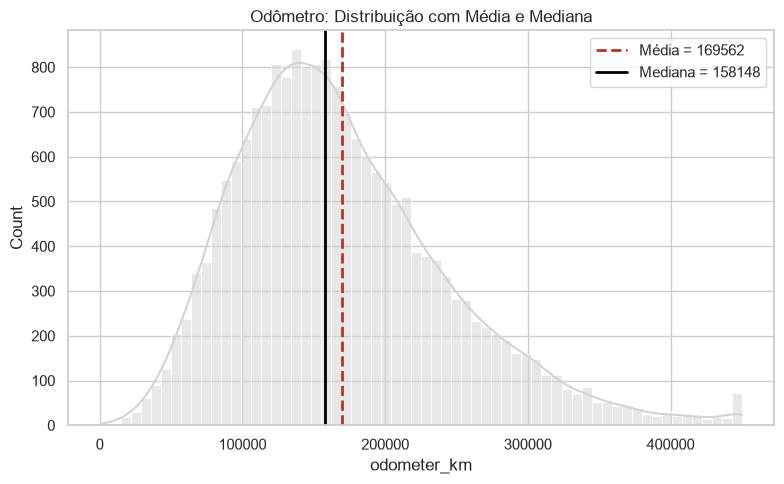

In [17]:
media_odometer = df["odometer_km"].mean()
mediana_odometer = df["odometer_km"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="odometer_km", kde=True, color=COR_NEUTRA)
plt.axvline(media_odometer, color=COR_DESTAQUE, linestyle="--", linewidth=2, label=f"Média = {media_odometer:.0f}")
plt.axvline(mediana_odometer, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_odometer:.0f}")
plt.title("Odômetro: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()


A média fica acima da mediana (~169.5k km vs ~158.1k km), assinatura típica de
assimetria à direita: alguns veículos com quilometragem bem alta puxam a média pra cima, sem
mudar tanto a mediana. Isso já indica que, na hora de imputar ausentes em `odometer_km`, a
**mediana** é a escolha mais robusta (a média seria distorcida pela cauda).


### Dispersão

In [18]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)


,var,std,IQR
manufacturing_year,8.200000e+00,2.86,5.00
battery_capacity_kwh,1.283880e+03,35.83,62.25
odometer_km,5.589310e+09,74761.69,95397.45


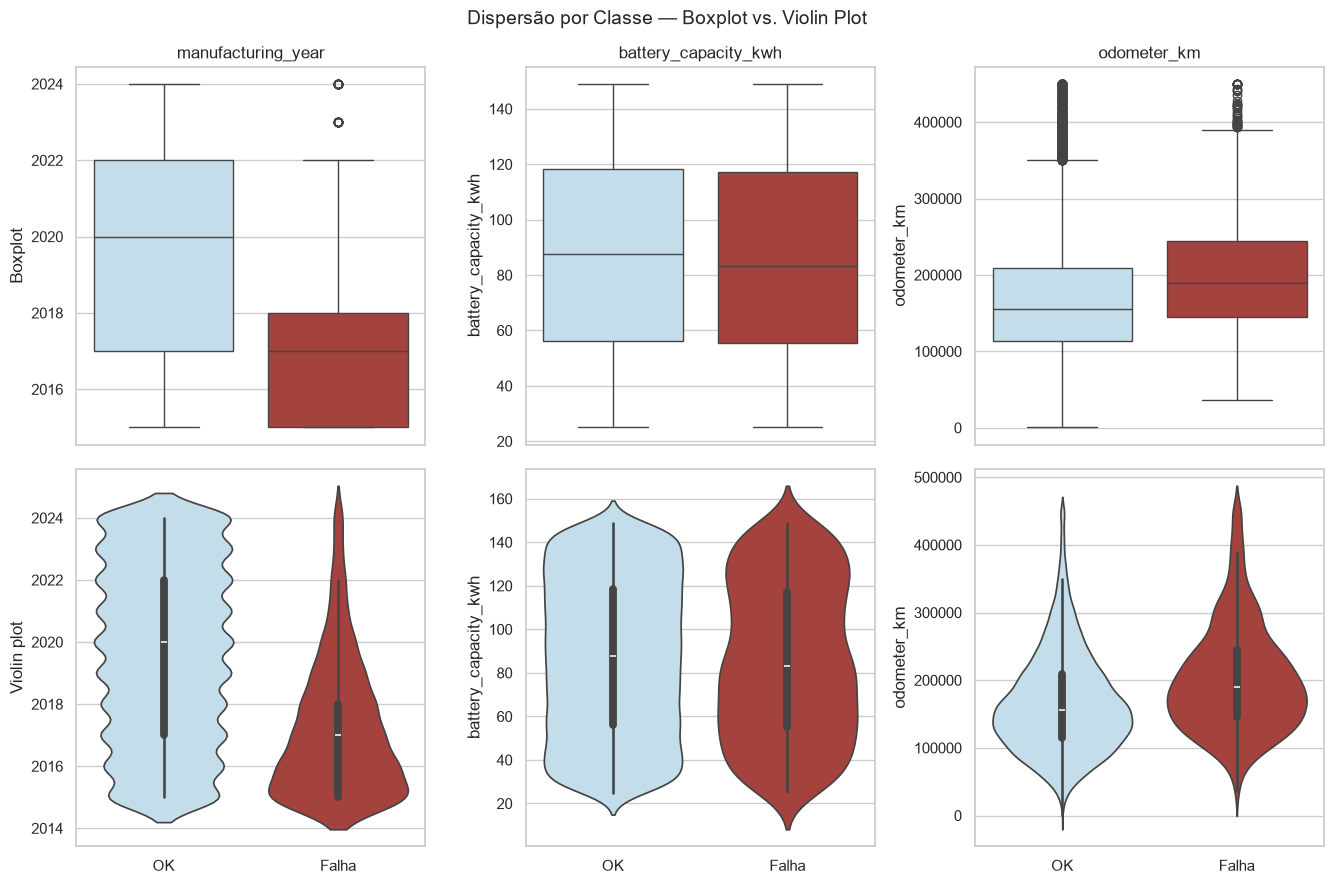

In [19]:
palette_classe = {"OK": COR_CONTEXTO, "Falha": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4.5 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="status_bateria", y=col, hue="status_bateria",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="status_bateria", y=col, hue="status_bateria",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()


**Discussão:** as caixas de `manufacturing_year` e `odometer_km` já aparecem deslocadas
entre "OK" e "Falha" (anos mais recentes / quilometragem menor no grupo OK), enquanto
`battery_capacity_kwh` mostra caixas quase sobrepostas, reforçando a suspeita de que a
capacidade da bateria, isoladamente, não separa bem as duas classes. Isso é indício, ainda
antes da bivariada formal, de que `manufacturing_year` e `odometer_km` devem ser variáveis mais
úteis para diferenciar veículos com e sem falha do que `battery_capacity_kwh`.


## 4. Tratamento de Dados Ausentes e Outliers


### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [20]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col].dropna())
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T


,limite_inferior,limite_superior,n_outliers
manufacturing_year,2009.50,2029.50,0.0
battery_capacity_kwh,-37.33,211.68,0.0
odometer_km,-26990.73,354599.08,417.0


### Visualizando os Outliers

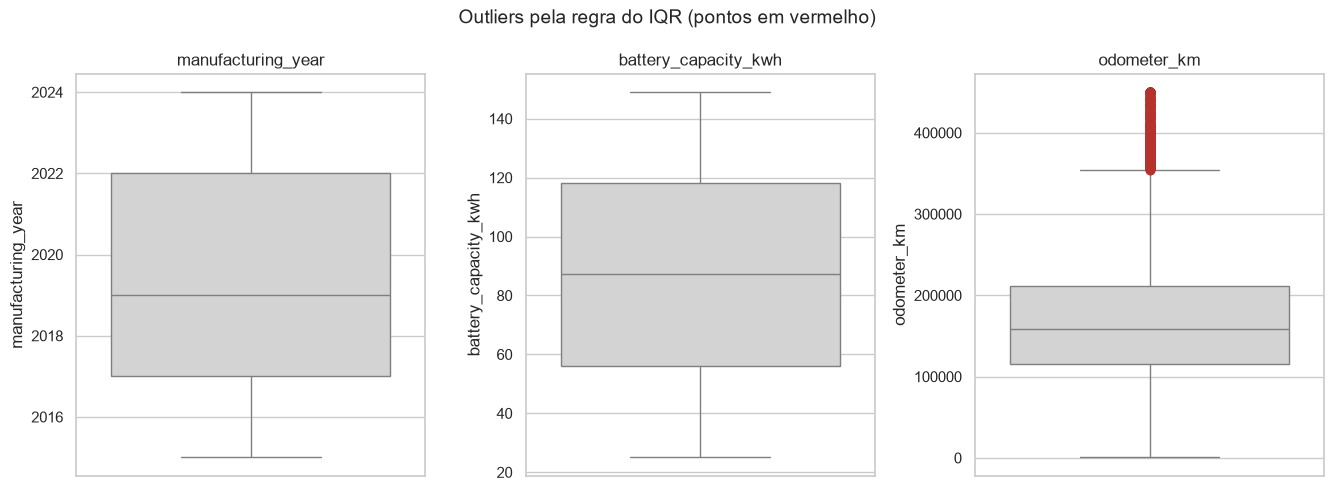

In [21]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4.5 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_DESTAQUE, markeredgecolor=COR_DESTAQUE, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()


**Discussão:** `manufacturing_year` e `battery_capacity_kwh` não têm nenhum outlier pela
regra do IQR (os limites calculados, ex: 2009 a 2029 para o ano, ficam bem mais largos que o
range real dos dados). Só `odometer_km` tem outliers (417 veículos acima de ~355 mil km).

Usando a mesma tabela de classificação da Aula 9/11:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Um veículo elétrico rodar 400-450 mil km ao longo de vários anos de uso (ex: frota, táxi,
aplicativo) é raro, mas **fisicamente plausível**, não viola nenhuma regra física nem de
negócio, e não há valores negativos ou absurdos (como km negativo) que indiquem erro de coleta.
Classifico como outlier **estatístico legítimo**.


### Decidindo o Tratamento dos Dados Ausentes

Na Aula 11, com ausência em só 2 colunas e ~2% das linhas afetadas, a decisão foi
remover as linhas. **Aqui a conclusão é diferente**,por quê: mesmo com
cada coluna isolada tendo só ~3-4% de ausentes, o fato de **9 colunas** serem afetadas
independentemente faz o efeito se acumular, o que interessa não é o ausente por coluna, e sim
quantas *linhas* sobrariam se eu removesse qualquer linha com pelo menos um ausente.


In [22]:
linhas_com_algum_ausente = df.isna().any(axis=1).sum()
print(f"Linhas com pelo menos 1 ausente: {linhas_com_algum_ausente} ({linhas_com_algum_ausente/len(df)*100:.1f}% do total)")
print(f"Linhas completas (0 ausentes): {(~df.isna().any(axis=1)).sum()}")


Linhas com pelo menos 1 ausente: 5789 (28.9% do total)
Linhas completas (0 ausentes): 14211


Quase **29% das linhas** têm ao menos um ausente, bem diferente dos ~2% do Heart
Disease. Remover essas linhas jogaria fora quase um terço do dataset, um custo alto demais
frente ao ganho de "simplicidade" que a remoção traria. Como o mecanismo de ausência (Seção 2)
aponta para MCAR/MAR (ausências independentes entre si e majoritariamente não associadas ao
alvo), **imputar** é a escolha mais defensável aqui:

- **Variáveis quantitativas** (`manufacturing_year`, `battery_capacity_kwh`, `odometer_km`):
  imputo com a **mediana** de cada coluna, mais robusta que a média, especialmente em
  `odometer_km`, que já vimos ser assimétrica.
- **Variáveis qualitativas**: em vez de imputar com a moda (o que infla artificialmente a
  categoria mais comum), crio uma categoria explícita `"Desconhecido"`. Isso preserva o sinal
  de "este dado não foi coletado" sem inventar uma marca/modelo que o veículo pode não ter.


In [23]:
linhas_antes = df.shape[0]
df_antes = df.copy()  

df["manufacturing_year"] = df["manufacturing_year"].fillna(df["manufacturing_year"].median())
df["battery_capacity_kwh"] = df["battery_capacity_kwh"].fillna(df["battery_capacity_kwh"].median())
df["odometer_km"] = df["odometer_km"].fillna(df["odometer_km"].median())

for col in VARS_QUALI:
    df[col] = df[col].fillna("Desconhecido")

print(f"Linhas antes: {linhas_antes} | Linhas depois: {df.shape[0]} (nenhuma linha removida)")
print(f"Total de ausentes restantes: {df.isna().sum().sum()}")


Linhas antes: 20000 | Linhas depois: 20000 (nenhuma linha removida)
Total de ausentes restantes: 0


### Decidindo o Tratamento dos Outliers

Como classifiquei os outliers de `odometer_km` como **estatísticos legítimos**, sigo a
mesma lógica da aula: **não removo**. A informação é real (veículos que rodaram muito são
justamente candidatos naturais a mais desgaste de bateria) e pode ser relevante para o alvo.
Com uma demonstração, podemos ver como ficaria uma transformação logarítmica caso a assimetria
atrapalhe algum teste/modelo mais à frente.


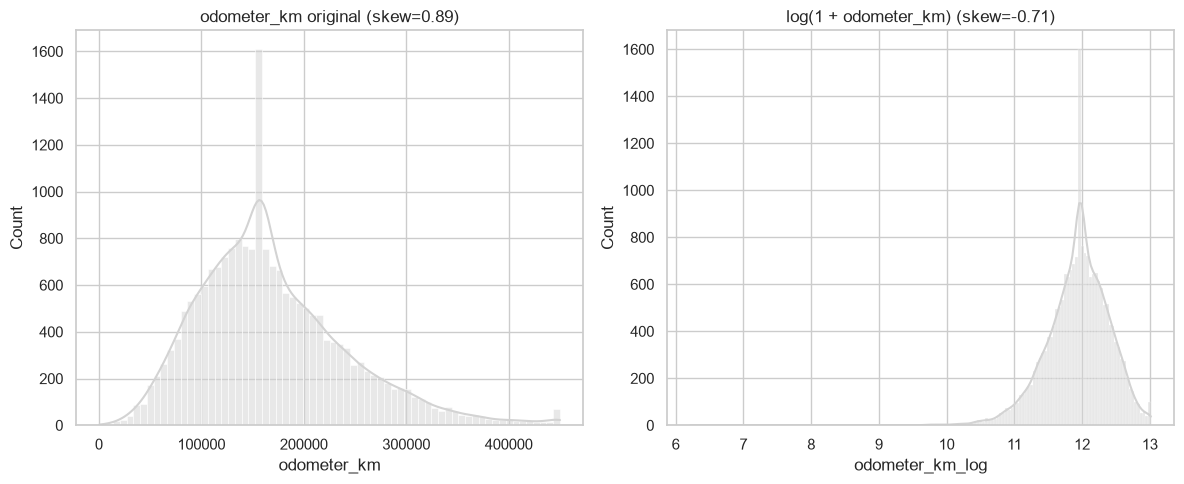

In [24]:
df["odometer_km_log"] = np.log1p(df["odometer_km"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="odometer_km", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"odometer_km original (skew={df['odometer_km'].skew():.2f})")

sns.histplot(data=df, x="odometer_km_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + odometer_km) (skew={df['odometer_km_log'].skew():.2f})")

plt.tight_layout()
plt.show()


A transformação log reduz visivelmente a assimetria (skew cai de ~0.89 para bem perto de
0). Mantenho `odometer_km_log` só como coluna de demonstração, não a uso nas próximas seções,
mas fica disponível caso um teste paramétrico ou modelo futuro exija dados mais simétricos.


## 5. Estatística Descritiva pt 2


In [25]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)


,mean,median,std,min,max,skewness,kurtosis
manufacturing_year,2019.47,2019.00,2.80,2015.00,2024.00,0.03,-1.13
battery_capacity_kwh,87.13,87.32,35.21,25.00,149.01,-0.01,-1.14
odometer_km,169067.84,158148.00,73162.00,500.00,450000.00,0.89,1.05


### Comparando "antes" x "depois"

In [26]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)


,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
manufacturing_year,0.006,0.031,-1.214,-1.126,0.026,0.088
battery_capacity_kwh,-0.006,-0.007,-1.207,-1.143,-0.001,0.064
odometer_km,0.850,0.888,0.864,1.055,0.038,0.191


**Discussão:** os deltas são pequenos (na casa de 0.03-0.19), mesmo tendo imputado
ausentes em ~29% das linhas, bem diferente do que se poderia imaginar. Isso confirma que a
imputação pela mediana foi **conservadora**: por definição, ela empurra os valores ausentes
para o centro da distribuição, então não deveria alterar drasticamente forma/assimetria. Pouca
mudança aqui é sinal de que o tratamento funcionou como esperado, não de que ele foi inútil.


**O odômetro ainda rejeita normalidade?**

In [27]:
amostra_antes = df_antes["odometer_km"].dropna().sample(4000, random_state=42)
amostra_depois = df["odometer_km"].sample(4000, random_state=42)

stat_sw_antes, p_valor_sw_antes = stats.shapiro(amostra_antes)
stat_sw_depois, p_valor_sw_depois = stats.shapiro(amostra_depois)

print(f"Shapiro-Wilk (antes)  — odometer_km: estatística={stat_sw_antes:.4f}, p-valor={p_valor_sw_antes:.4g}")
print(f"Shapiro-Wilk (depois) — odometer_km: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")


Shapiro-Wilk (antes)  — odometer_km: estatística=0.9602, p-valor=8.567e-32
Shapiro-Wilk (depois) — odometer_km: estatística=0.9494, p-valor=4.617e-35


Continua rejeitando normalidade nos dois casos, a imputação não mudou essa conclusão.

**Visualizando antes x depois, lado a lado**

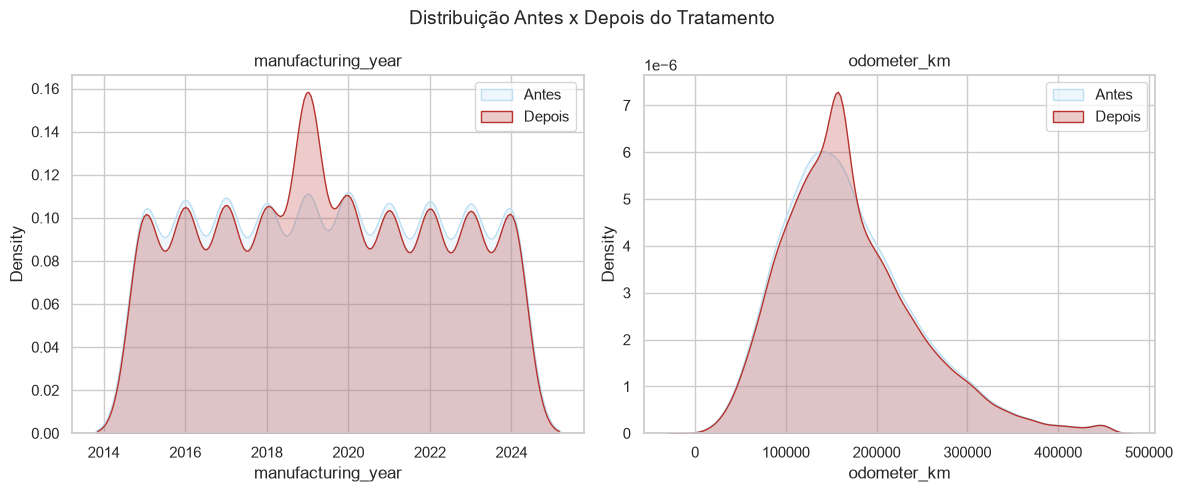

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["manufacturing_year", "odometer_km"]):
    sns.kdeplot(df_antes[col].dropna(), color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()


As curvas "antes" e "depois" praticamente se sobrepõem, mesmo com quase 30% das linhas
tendo recebido algum valor imputado. Isso confirma visualmente o que já víamos na tabela de
skew/kurtosis: a imputação pela mediana preservou bem o formato original da distribuição.


## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora avalio frequência e desbalanceamento das variáveis qualitativas. Excluo
`vehicle_model` das tabelas/gráficos de frequência (tem 42 categorias, cardinalidade alta
demais para uma tabela ou gráfico de barras legível), mas ela já entrou na análise de
ausentes/desbalanceamento onde fazia sentido.


#### Frequências absolutas e relativas

In [29]:
VARS_QUALI_FREQ = ["vehicle_brand", "vehicle_type", "battery_manufacturer", "battery_chemistry", "drive_type"]

for col in VARS_QUALI_FREQ:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))



--- vehicle_brand ---
               absoluta  relativa
vehicle_brand                    
BYD                1007     0.050
Mercedes-Benz      1006     0.050
Audi               1005     0.050
Renault            1003     0.050
Volkswagen          992     0.050
Kia                 992     0.050
BMW                 991     0.050
Honda               988     0.049
Tesla               980     0.049
Nissan              978     0.049
Hyundai             977     0.049
Mahindra            964     0.048
Tata                960     0.048
GM                  958     0.048
Lucid               953     0.048
MG                  947     0.047
Volvo               931     0.047
Porsche             913     0.046
Rivian              912     0.046
Ford                899     0.045
Desconhecido        644     0.032

--- vehicle_type ---
              absoluta  relativa
vehicle_type                    
Hatchback         3266     0.163
Crossover         3234     0.162
Van               3232     0.162
Truck   

#### Visualizando as frequências

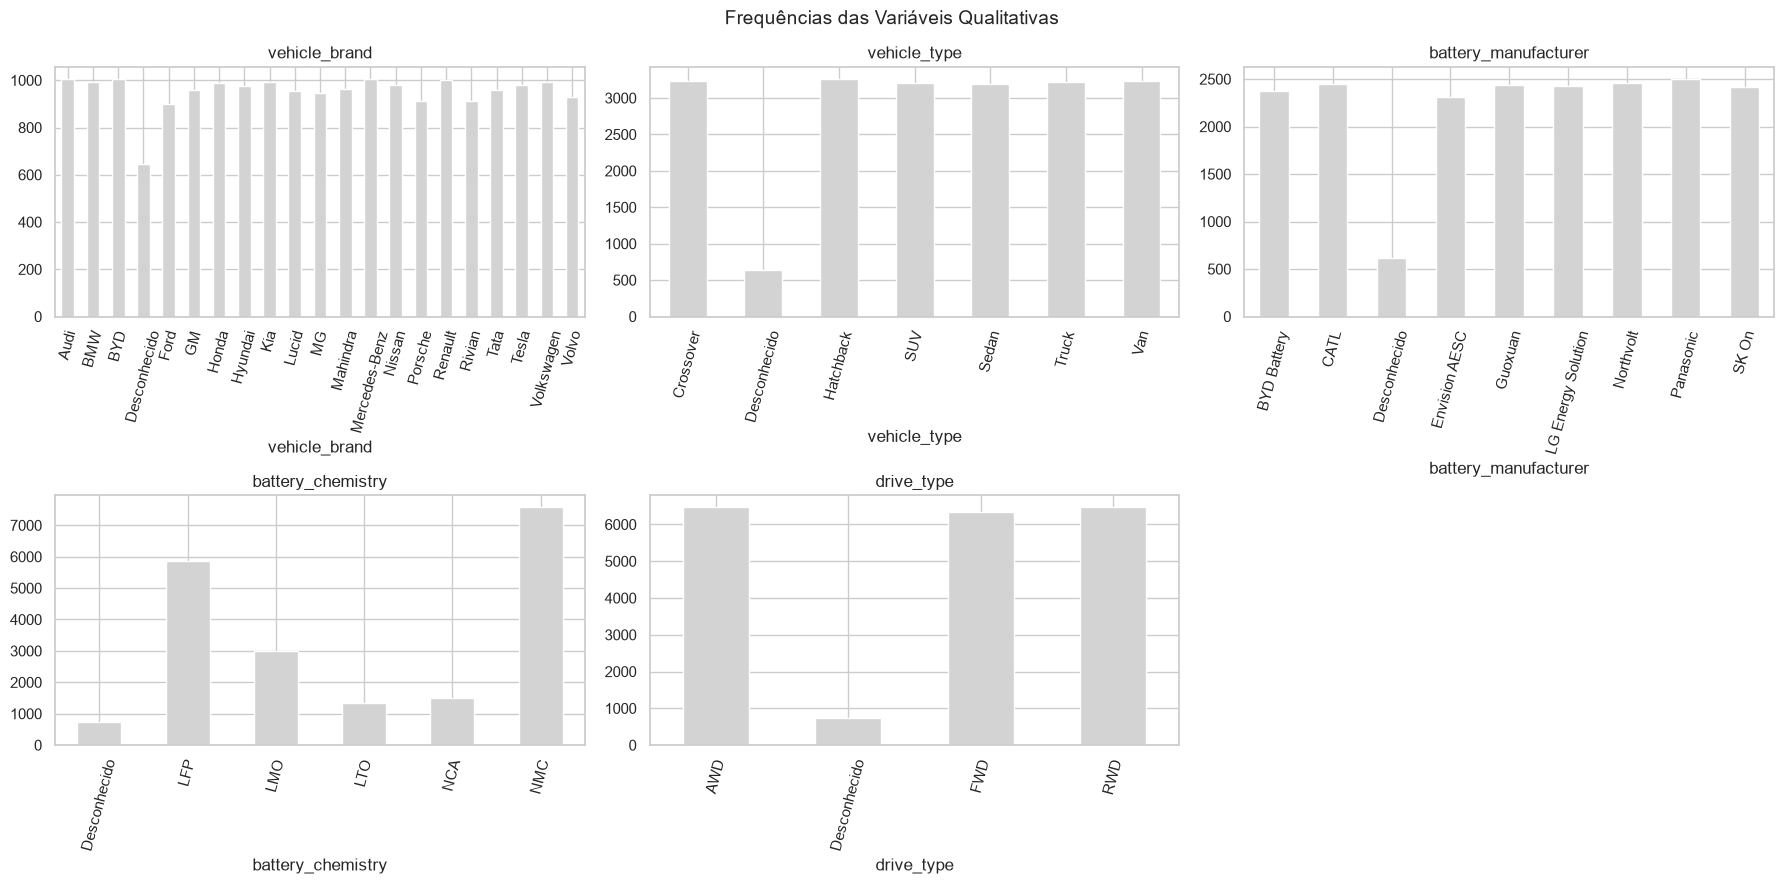

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI_FREQ):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=75)

for ax in axes[len(VARS_QUALI_FREQ):]:
    ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()


**Discussão:** `vehicle_brand`, `vehicle_type`, `battery_manufacturer` e `drive_type`
estão bem distribuídos entre suas categorias (nenhuma domina). `battery_chemistry` é a exceção:
NMC (~38% das linhas) e LFP (~29%) juntas concentram boa parte dos veículos, enquanto LTO fica
bem menos representada. Isso pode afetar cruzamentos futuros envolvendo `battery_chemistry`,
categorias raras (como LTO) terão contagens pequenas em qualquer crosstab, tornando testes de
associação com elas menos confiáveis.


#### Desbalanceamento entre Classes

- **Razão de desbalanceamento**: # classe majoritária / # classe minoritária.
- **Entropia de Shannon normalizada**: 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Aplico as duas em todas as qualitativas de frequência, **incluindo o próprio alvo**
`status_bateria`, esse é o ponto mais importante desta subseção.


In [31]:
def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI_FREQ + ["status_bateria"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T


,n_classes,razao_desbalanceamento,entropia_normalizada
vehicle_brand,21.0,1.56,0.999
vehicle_type,7.0,5.07,0.964
battery_manufacturer,9.0,4.05,0.980
battery_chemistry,6.0,10.49,0.841
drive_type,4.0,8.91,0.876
status_bateria,2.0,13.45,0.363


**Discussão :** `status_bateria` (o alvo) tem
razão de desbalanceamento de **~13.4x** e entropia de só **0.363**, ou seja, cerca de 93% dos
veículos são "OK" e só ~7% tiveram falha. Isso é um forte desbalanceamento de classes, bem
diferente do Heart Disease (onde as duas classes eram relativamente próximas). Qualquer análise
bivariada ou modelo treinado sobre esse alvo precisa levar esse desbalanceamento em conta (ex:
acurácia bruta seria enganosa, um modelo que sempre prevê "OK" já acertaria ~93%). As demais
qualitativas ficam bem mais equilibradas (entropia perto de 1), com `battery_chemistry` sendo a
segunda mais desbalanceada (razão 5.6x), como já era visível no gráfico de barras.


### Análise Bivariada

Agora avalio como as variáveis de fato se relacionam entre si e com o alvo `status_bateria`.

#### Quantitativa x Quantitativa — Correlação

Como nenhuma das quantitativas passou no Shapiro-Wilk (Seção 3), Spearman é a escolha
mais segura, mas calculo as três (Pearson, Spearman, Kendall) para comparar.


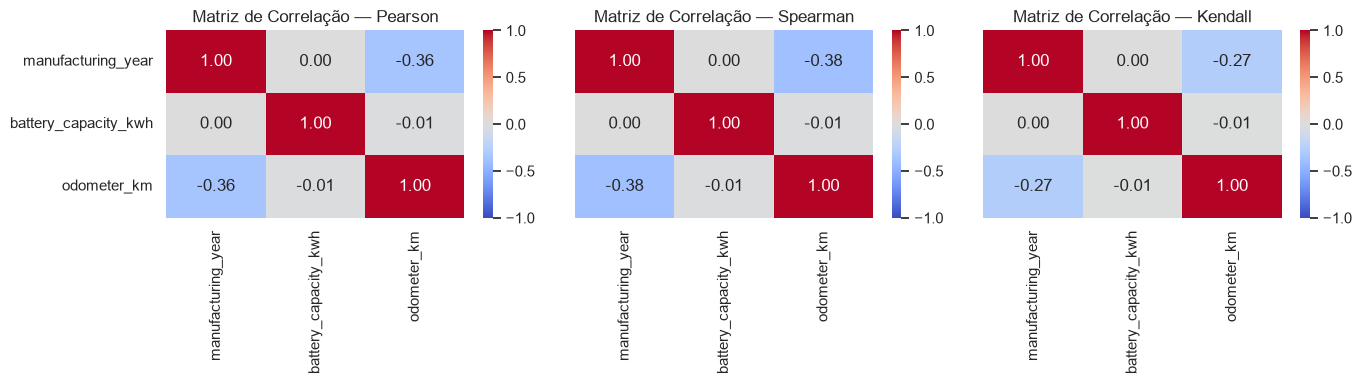

In [32]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


**Discussão:** Pearson e Spearman concordam bem entre si (sem grandes divergências, o que
sugere que a relação entre as variáveis, quando existe, é razoavelmente linear/monotônica sem
distorções fortes). A correlação mais evidente é entre `manufacturing_year` e `odometer_km`
(~ -0.40, moderada): veículos mais novos tendem a ter rodado menos quilômetros, relação
fisiológica esperada, não uma coincidência estatística. `battery_capacity_kwh` não mostra
correlação relevante com nenhuma das outras duas (perto de 0), reforçando que ela parece
"independente" no dataset.


#### Dispersão (scatter) entre duas variáveis quantitativas

Escolho `manufacturing_year` x `odometer_km` por motivo de domínio (a correlação
encontrada acima) e não só estatístico, existe uma relação de uso real entre ano do veículo e
quilometragem acumulada.


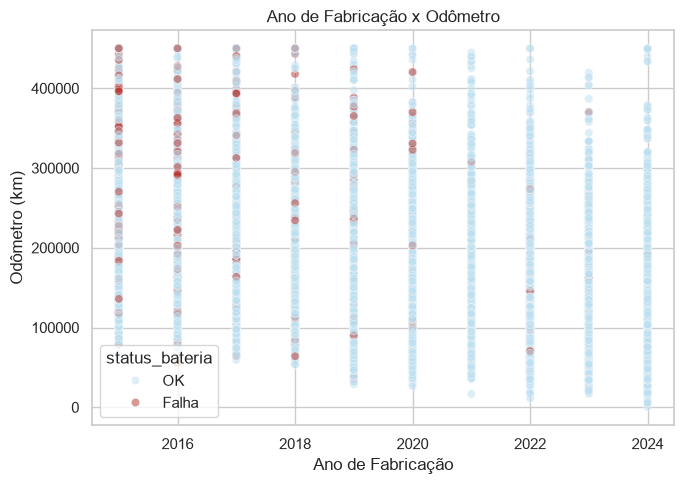

In [33]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="manufacturing_year", y="odometer_km", hue="status_bateria",
                palette={"OK": COR_CONTEXTO, "Falha": COR_DESTAQUE}, alpha=0.5)
plt.title("Ano de Fabricação x Odômetro")
plt.xlabel("Ano de Fabricação")
plt.ylabel("Odômetro (km)")
plt.tight_layout()
plt.show()


**Discussão:** dá pra ver a tendência de queda esperada (quanto mais recente o veículo,
menor a quilometragem acumulada). Os pontos vermelhos ("Falha") aparecem mais concentrados na
região de veículos mais antigos e/ou com mais quilometragem, coerente com o que a ECDF e os
boxplots por classe já sugeriam na Seção 3.


#### Quantitativa x Qualitativa: Comparando Grupos

Já vimos (Seção 3) que **nenhuma** das quantitativas passa no Shapiro-Wilk. Isso significa
que, tecnicamente, deveria usar o equivalente não-paramétrico do T-Test: o **Mann-Whitney U**
(já que o alvo tem só 2 grupos: OK/Falha). Calculo T-Test e Mann-Whitney lado a lado, mas o
resultado não-paramétrico é o que deve ser reportado como principal.


In [34]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_ok = df.loc[df["status_bateria"] == "OK", col]
    grupo_falha = df.loc[df["status_bateria"] == "Falha", col]

    stat_t, p_t = stats.ttest_ind(grupo_ok, grupo_falha, equal_var=False)   
    stat_u, p_u = stats.mannwhitneyu(grupo_ok, grupo_falha)                 

    resultados_comparacao.append({
        "variavel": col,
        "mediana_OK": round(grupo_ok.median(), 2),
        "mediana_Falha": round(grupo_falha.median(), 2),
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")


,mediana_OK,mediana_Falha,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,,,
manufacturing_year,2019.00,2017.00,0.00000,0.00000,True
battery_capacity_kwh,87.32,86.22,0.11996,0.11013,True
odometer_km,158148.00,185075.15,0.00000,0.00000,True


**Discussão:** T-Test e Mann-Whitney concordam nas três variáveis. `manufacturing_year`
e `odometer_km` mostram diferença estatisticamente significativa entre "OK" e "Falha" (mediana
de fabricação mais recente e odômetro menor no grupo "OK"), enquanto `battery_capacity_kwh`
**não** mostra diferença significativa, confirmando estatisticamente a suspeita que já tinha
desde os boxplots da Seção 3: capacidade da bateria isolada não parece influenciar a falha,
enquanto idade do veículo e quilometragem acumulada sim.


#### Qualitativa x Qualitativa (alvo): Qui-Quadrado

Testo associação entre cada variável qualitativa e o alvo `status_bateria`, com o
Qui-Quadrado de independência.


In [35]:
resultados_chi2 = []
for col in VARS_QUALI_FREQ:
    tabela = pd.crosstab(df[col], df["status_bateria"])
    chi2, p, gl, esperado = stats.chi2_contingency(tabela)
    resultados_chi2.append({"variavel": col, "chi2": round(chi2, 2), "p_valor": round(p, 4),
                             "associado_ao_alvo": p < 0.05})

pd.DataFrame(resultados_chi2).set_index("variavel")


,chi2,p_valor,associado_ao_alvo
variavel,,,
vehicle_brand,12.68,0.8905,False
vehicle_type,4.29,0.6371,False
battery_manufacturer,4.60,0.7992,False
battery_chemistry,4.34,0.5017,False
drive_type,0.68,0.8782,False


**Discussão:** nenhuma das qualitativas (marca, tipo de veículo, fabricante da bateria,
química da bateria, tração) mostra associação estatisticamente significativa com
`status_bateria` (todos os p-valores bem acima de 0.05). Isso é um achado interessante: sugere
que, neste dataset, a falha de bateria parece explicada por variáveis de **uso/idade**
(`manufacturing_year`, `odometer_km`) e não por atributos de fabricação/especificação do
veículo ou da bateria em si.Usando um heatmap de exemplo (`battery_chemistry`), só para visualizar a distribuição.


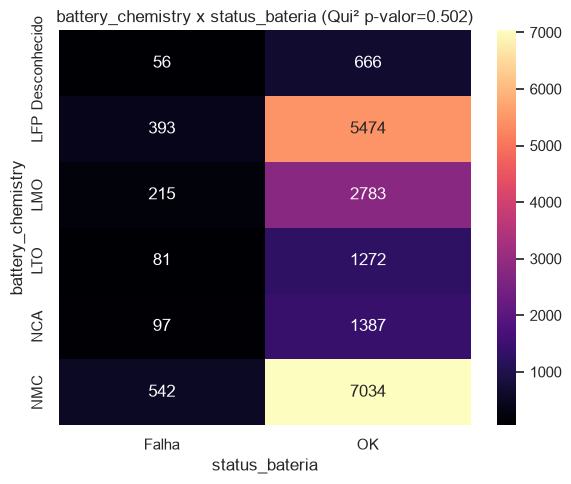

In [36]:
contingencia_chem = pd.crosstab(df["battery_chemistry"], df["status_bateria"])
chi2_chem, p_chem, _, _ = stats.chi2_contingency(contingencia_chem)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_chem, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"battery_chemistry x status_bateria (Qui² p-valor={p_chem:.3g})")
plt.tight_layout()
plt.show()


#### Avaliação por subgrupos

Adaptando a seção de fairness da Aula 11 (lá aplicada a sexo/faixa etária): aqui não há
atributos sensíveis no sentido demográfico, mas a mesma pergunta continua válida em outro
contexto — **a proporção de falha se comporta igual entre diferentes segmentos de produto**
(marca do veículo e química da bateria)? Se um segmento específico concentrar taxa de falha bem
mais alta, isso merece investigação (ex: lote defeituoso, especificação inadequada), mesmo que o
Qui-Quadrado geral não tenha acusado associação forte.


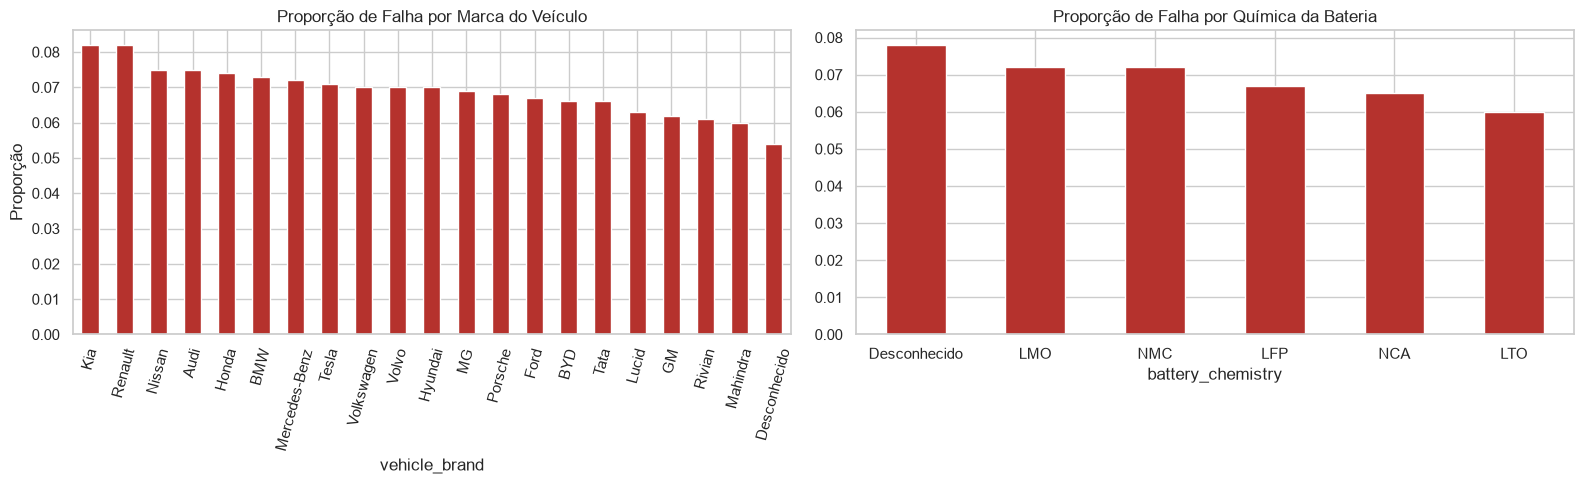

In [37]:
prop_por_marca = pd.crosstab(df["vehicle_brand"], df["status_bateria"], normalize="index").round(3)
prop_por_quimica = pd.crosstab(df["battery_chemistry"], df["status_bateria"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

prop_por_marca["Falha"].sort_values(ascending=False).plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção de Falha por Marca do Veículo")
axes[0].set_ylabel("Proporção")
axes[0].tick_params(axis="x", rotation=75)

prop_por_quimica["Falha"].sort_values(ascending=False).plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção de Falha por Química da Bateria")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


**Discussão:** as proporções de falha variam pouco entre marcas e entre químicas de
bateria, nenhuma se destaca de forma isolada, o que é coerente com o Qui-Quadrado não
significativo visto acima. Não há, neste dataset, indício de que algum segmento específico de
marca ou química concentre desproporcionalmente as falhas.


#### Outliers bivariados

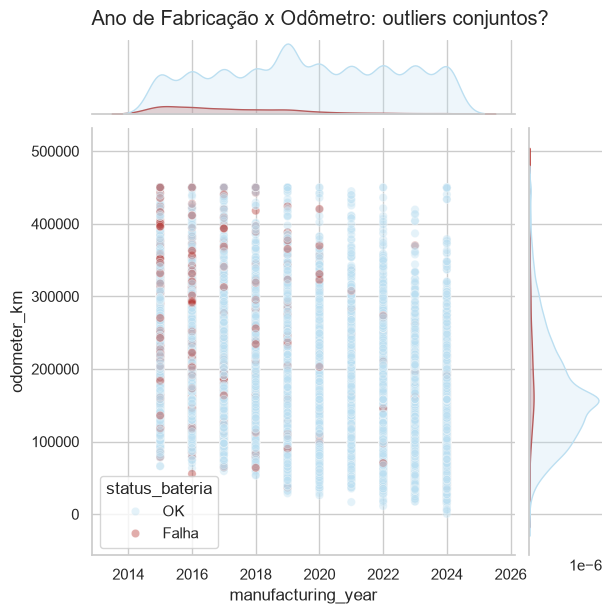

In [38]:
sns.jointplot(data=df, x="manufacturing_year", y="odometer_km", hue="status_bateria",
              palette={"OK": COR_CONTEXTO, "Falha": COR_DESTAQUE}, alpha=0.4, height=6)
plt.suptitle("Ano de Fabricação x Odômetro: outliers conjuntos?", y=1.02)
plt.show()


**Discussão:** o canto superior-esquerdo (veículos antigos com quilometragem baixa) e o
inferior-direito (veículos novos com quilometragem alta) concentram poucos pontos, são
combinações incomuns mesmo que os valores individuais de cada variável não sejam outliers
univariados. Não são erros óbvios (nenhum viola limite físico), mas são casos que mereceriam
uma segunda checagem se este dataset alimentasse um modelo mais adiante.


### Análise Multivariada

##### Matriz de Correlação

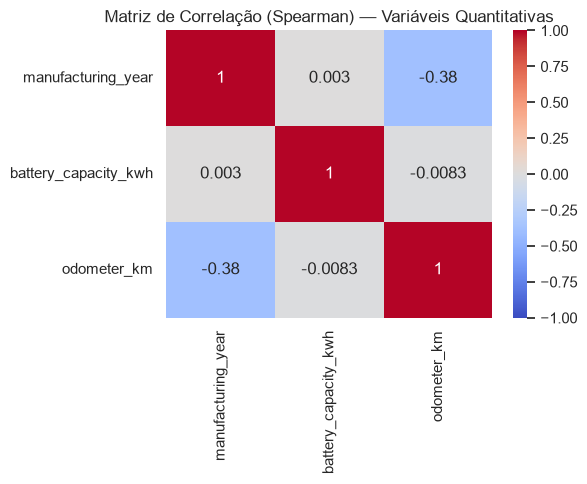

In [39]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:** |r| < 0.3 ~ fraca; 0.3 < |r| < 0.7 ~ moderada; |r| > 0.7 ~ forte.

A única correlação que chama atenção é `manufacturing_year` x `odometer_km` (~-0.40, moderada) —
já discutida acima. Não há sinal de redundância forte (|r| > 0.7) entre nenhum par, então não há
motivo, por ora, para descartar alguma dessas três variáveis por multicolinearidade.


##### Correlograma

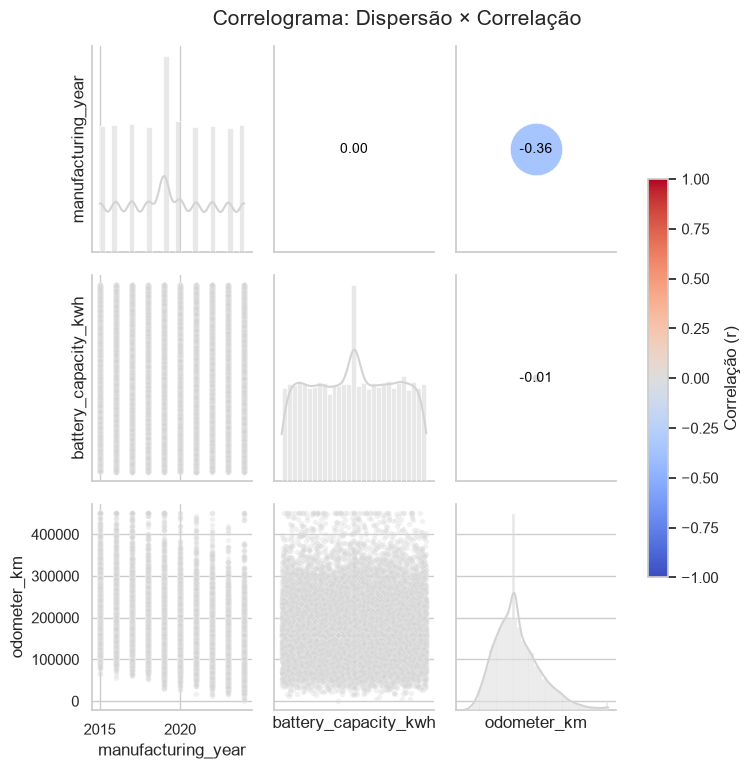

In [40]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.3, s=15)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)
plt.show()


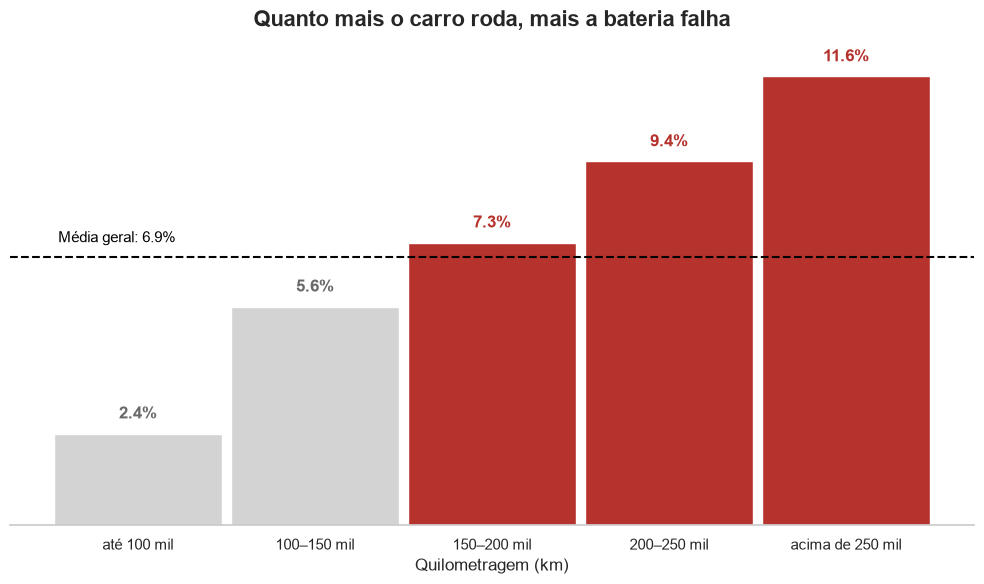

In [44]:
# Big Idea: o desgaste por uso explica as falhas
base = df_antes.dropna(subset=["odometer_km"]).copy()

# Faixas de quilometragem
limites = [0, 100_000, 150_000, 200_000, 250_000, np.inf]
rotulos = ["até 100 mil", "100–150 mil", "150–200 mil", "200–250 mil", "acima de 250 mil"]
base["faixa_km"] = pd.cut(base["odometer_km"], bins=limites, labels=rotulos, right=False)

# Taxa de falha por faixa (em %) e taxa média geral
taxa = base.groupby("faixa_km", observed=True)["battery_failure"].mean() * 100
taxa_media = base["battery_failure"].mean() * 100

# Cor: vermelho só para quem está acima da média
cores = [COR_DESTAQUE if t > taxa_media else COR_NEUTRA for t in taxa]

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar(taxa.index.astype(str), taxa.values, color=cores, width=0.95)

# Linha da média como régua (rótulo à esquerda, sobre o espaço livre)
ax.axhline(taxa_media, color=COR_ALERTA, linestyle="--", linewidth=1.5)
ax.text(-0.45, taxa_media + 0.3, f"Média geral: {taxa_media:.1f}%",
        ha="left", va="bottom", fontsize=11, color=COR_ALERTA)

# Rótulos diretos nas barras
for barra, t in zip(barras, taxa.values):
    ax.text(barra.get_x() + barra.get_width() / 2, t + 0.3, f"{t:.1f}%",
            ha="center", va="bottom", fontsize=12, fontweight="bold",
            color=COR_DESTAQUE if t > taxa_media else "dimgray")

# Título centralizado com a mensagem
ax.set_title("Quanto mais o carro roda, mais a bateria falha",
             fontsize=16, fontweight="bold", loc="center", pad=20)
ax.set_xlabel("Quilometragem (km)", fontsize=12)

# Limpeza: sem grade, bordas nem eixo Y (os rótulos já dizem tudo)
ax.grid(False)
ax.set_yticks([])
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)

plt.tight_layout()
plt.show()

## Conclusões

**Principais achados:**

1. **O alvo é fortemente desbalanceado** (~93% OK / ~7% Falha, razão ~13.4x). Qualquer
   modelagem futura precisa considerar isso (ex: métricas além de acurácia, balanceamento de
   classes).
2. **Idade e uso do veículo importam, especificação não:** `manufacturing_year` e
   `odometer_km` mostram diferença estatisticamente significativa entre veículos "OK" e "Falha"
   (Mann-Whitney), enquanto `battery_capacity_kwh` e todas as variáveis qualitativas (marca,
   tipo, fabricante da bateria, química, tração) não mostram associação significativa com o
   alvo. Isso sugere que o desgaste por uso pesa mais do que a especificação do produto neste
   dataset.
3. **Ausência de dados generalizada, mas provavelmente aleatória (MCAR):** 9 das 11 colunas têm
   ausentes (~3-4% cada), somando ~29% das linhas com pelo menos um ausente. Os indicadores de
   ausência não se correlacionam entre si nem (majoritariamente) com o alvo, por isso optei por
   **imputar** (mediana para quantitativas, categoria "Desconhecido" para qualitativas) em vez de
   remover linhas, decisão diferente da tomada na Aula 11 (lá o volume era pequeno o bastante
   para justificar a remoção).
4. **Nenhuma variável quantitativa é normal** (Shapiro-Wilk rejeita as três), então análises
   futuras que dependam de normalidade devem preferir testes não-paramétricos (como já apliquei
   aqui) ou transformações (demonstrei o log em `odometer_km`).
5. **Outliers de `odometer_km` são legítimos**, não erros de coleta, optei por mantê-los, já
   que representam veículos reais de alta quilometragem, informação potencialmente relevante
   para o próprio alvo de falha.

## Declaração de Uso de IA

- **Ferramenta utilizada:** Claude (Anthropic).
- **Para o que foi aplicada:** Auxiliando na elaboração de graficos e recursos visuais que auxiliem na interpretação dos dados, além de auxiliar na parte da documentação e descrição do que foi feito ( melhorando e corrigindo os textos ).


## Exportação para o dashboard
Execute o notebook do início ao fim antes desta célula. O app utiliza somente o dataset tratado; o arquivo original permanece em `data/raw/`.

In [ ]:
pasta_clean = RAIZ / "data" / "clean"
pasta_clean.mkdir(parents=True, exist_ok=True)
df.to_csv(pasta_clean / "dataset.csv", index=False)
print(f"Dataset tratado exportado: {len(df)} veículos e {len(df.columns)} colunas.")
